In [8]:
#!pip install botorch
#!pip install pyDOE
#!pip install openpyxl

In [9]:
# Support for math
import numpy as np
import math

# Plotting tools
from matplotlib import pyplot as plt
import matplotlib

import warnings
warnings.filterwarnings('ignore')

# GPy: Gaussian processes library
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF


#File Tools for local
import pandas as pd

#Sampling
from pyDOE import lhs

#BO torch
import torch
import gpytorch
from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from botorch.utils import standardize
from gpytorch.mlls import ExactMarginalLogLikelihood

#Generate points

In [10]:
from pyDOE import lhs
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # Step 1: Generate Latin Hypercube Samples
    seed
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # Step 2: Transform samples to satisfy the sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

sampled_colors = latin_hypercube_sum_constraint(12, 3, 300,np.random.seed(2))//1
sampled_colors.transpose()

array([[ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
         15.],
       [ 39.,  76.,  78., 122., 128., 124., 153.,  37., 125., 100.,  39.,
         69.],
       [177.,  57., 116., 150.,  62.,  91., 114.,  47.,  59.,  59.,  46.,
        214.]])

In [11]:
test_colors = latin_hypercube_sum_constraint(8, 3, 300,np.random.seed(1))
test_colors.T

array([[ 63.71345478,  65.37859309, 112.58538392, 146.23075328,
        104.62865987, 209.01047487,  70.06274528,   7.63689549],
       [201.06725529, 132.82966093,  49.91098934, 109.7745757 ,
        114.62358182,  24.20451755, 132.23085965,  36.27034483],
       [ 35.21928992, 101.79174598, 137.50362674,  43.99467102,
         80.74775831,  66.78500758,  97.70639506, 256.09275968]])

#import data

In [12]:
# Path
xls = pd.read_excel("/Users/clarat/Documents/Sun Lab/Mara_colors/mara_color_data/02_23_Random_Color_Increment.xlsx",sheet_name=["End point","RGB"],engine='openpyxl')

df = xls.get('End point')
df_RGB = xls.get('RGB')

df.head()

,Well\nRow,Well\nCol,Content,Concentration,Raw Data (Abs Spectrum),Raw Data (Abs Spectrum).1,Raw Data (Abs Spectrum).2,Raw Data (Abs Spectrum).3,Raw Data (Abs Spectrum).4,Raw Data (Abs Spectrum).5,...,Raw Data (Abs Spectrum).141,Raw Data (Abs Spectrum).142,Raw Data (Abs Spectrum).143,Raw Data (Abs Spectrum).144,Raw Data (Abs Spectrum).145,Raw Data (Abs Spectrum).146,Raw Data (Abs Spectrum).147,Raw Data (Abs Spectrum).148,Raw Data (Abs Spectrum).149,Raw Data (Abs Spectrum).150
0,NaN,NaN,Wavelength [nm],NaN,400.000,402.000,404.000,406.000,408.000,410.000,...,682.000,684.000,686.000,688.000,690.000,692.000,694.000,696.000,698.000,700.000
1,D,1.0,Sample X37,74626.252,1.363,1.391,1.409,1.438,1.459,1.474,...,0.043,0.042,0.040,0.038,0.035,0.034,0.033,0.031,0.030,0.030
2,D,2.0,Sample X38,25529.573,0.627,0.648,0.663,0.677,0.689,0.694,...,0.066,0.061,0.056,0.051,0.047,0.043,0.041,0.037,0.036,0.035
3,D,3.0,Sample X39,42472.278,0.997,1.023,1.044,1.065,1.080,1.093,...,0.067,0.061,0.057,0.053,0.050,0.047,0.044,0.041,0.040,0.038
4,D,4.0,Sample X40,32500.649,1.461,1.497,1.528,1.560,1.574,1.584,...,0.277,0.267,0.260,0.253,0.247,0.243,0.239,0.236,0.234,0.231


Inputs

In [13]:
vol_red  = sampled_colors[:,0]
vol_blue = sampled_colors[:,1]
vol_yelo = sampled_colors[:,2]
vol_red

array([ 82., 165., 105.,  26., 109.,  84.,  32., 214., 114., 139., 214.,
        15.])

Outputs

In [14]:
colors_R = np.array(df_RGB.loc[:,'R/255'])
colors_G = np.array(df_RGB.loc[:,'G/255'])
colors_B = np.array(df_RGB.loc[:,'B/255'])

colors_RGB = list(zip(colors_R,colors_G,colors_B))

colors_RGB

[(0.3254901961, 0.2862745098, 0.07843137255),
 (0.1254901961, 0.1137254902, 0.1960784314),
 (0.137254902, 0.1803921569, 0.1490196078),
 (0.0, 0.3529411765, 0.2117647059),
 (0.003921568627, 0.1176470588, 0.2745098039),
 (0.0, 0.1450980392, 0.2156862745),
 (0.007843137255, 0.2941176471, 0.2666666667),
 (0.2470588235, 0.1098039216, 0.1882352941),
 (0.01176470588, 0.1215686275, 0.3058823529),
 (0.05882352941, 0.09411764706, 0.2549019608),
 (0.2117647059, 0.1176470588, 0.1725490196),
 (0.0, 0.5882352941, 0.07450980392)]

#Gaussian Process

Reference: https://gist.github.com/danhphan/af53fb7958a28c2e2d514221ea83bd9c

In [15]:
import torch
import gpytorch as gpt

In [16]:
volume = np.array(sampled_colors) # input
colors = np.array([colors_R,colors_G,colors_B]).T #output
x = volume
y = colors
# Reference RGB value (the desired or ideal RGB you want to achieve)
reference_rgb = np.array([160/255, 32/255, 240/255])

In [17]:
df_x = torch.tensor(volume, dtype=torch.float32)
df_y = torch.tensor(colors, dtype=torch.float32)

df_x.shape, df_y.shape

(torch.Size([12, 3]), torch.Size([12, 3]))

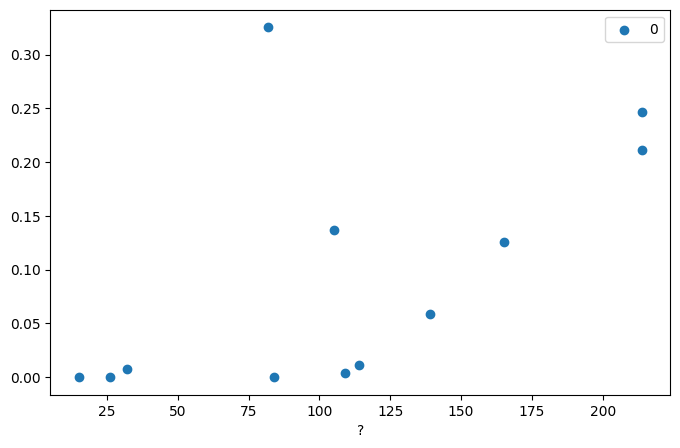

In [18]:
fig, ax = plt.subplots(1,1, figsize=(8,5))
ax.scatter(df_x.numpy()[:,0], df_y.numpy()[:,0])
plt.legend(["0"])
plt.xlabel("?")
plt.show()

In [19]:
class MultitaskGPModel(gpt.models.ExactGP):
    def __init__(self, x, y, likelihood):
        super(MultitaskGPModel, self).__init__(x, y, likelihood)
        self.mean_module = gpt.means.MultitaskMean(
            gpt.means.ConstantMean(), num_tasks=3
        )
        self.covar_module = gpt.kernels.MultitaskKernel(
            gpt.kernels.RBFKernel() + gpt.kernels.MaternKernel(), num_tasks=3, rank=3
        )
        
    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_module(x)
        return gpt.distributions.MultitaskMultivariateNormal(mean_x, covar_x)

In [20]:
likelihood = gpt.likelihoods.MultitaskGaussianLikelihood(num_tasks=3)
model = MultitaskGPModel(df_x, df_y, likelihood)

In [21]:
torch.reshape(df_y, (-1,)),model(df_x)

(tensor([0.3255, 0.2863, 0.0784, 0.1255, 0.1137, 0.1961, 0.1373, 0.1804, 0.1490,
         0.0000, 0.3529, 0.2118, 0.0039, 0.1176, 0.2745, 0.0000, 0.1451, 0.2157,
         0.0078, 0.2941, 0.2667, 0.2471, 0.1098, 0.1882, 0.0118, 0.1216, 0.3059,
         0.0588, 0.0941, 0.2549, 0.2118, 0.1176, 0.1725, 0.0000, 0.5882, 0.0745]),
 MultitaskMultivariateNormal(mean shape: torch.Size([12, 3])))

In [22]:
#Training the model
training_iters = 120

model.train()
likelihood.train()

optimizer = torch.optim.Adam(model.parameters(), lr=1e-1)
# Loss for the marginal log likelihood
mll = gpt.mlls.ExactMarginalLogLikelihood(likelihood, model)

for i in range(training_iters):
    optimizer.zero_grad()
    output = model(df_x)
    loss = -mll(output, torch.reshape(df_y, (-1,)))
    #loss = -mll(output, df_y)
    loss.backward()
    print('Iter %d/%d - Loss: %.3f' % (i + 1, training_iters, loss.item()))
    optimizer.step()

Iter 1/120 - Loss: 1.953
Iter 2/120 - Loss: 1.895
Iter 3/120 - Loss: 1.836
Iter 4/120 - Loss: 1.775
Iter 5/120 - Loss: 1.710
Iter 6/120 - Loss: 1.641
Iter 7/120 - Loss: 1.567
Iter 8/120 - Loss: 1.491
Iter 9/120 - Loss: 1.413
Iter 10/120 - Loss: 1.335
Iter 11/120 - Loss: 1.259
Iter 12/120 - Loss: 1.187
Iter 13/120 - Loss: 1.121
Iter 14/120 - Loss: 1.059
Iter 15/120 - Loss: 0.992
Iter 16/120 - Loss: 0.918
Iter 17/120 - Loss: 0.839
Iter 18/120 - Loss: 0.761
Iter 19/120 - Loss: 0.687
Iter 20/120 - Loss: 0.628
Iter 21/120 - Loss: 0.590
Iter 22/120 - Loss: 0.561
Iter 23/120 - Loss: 0.529
Iter 24/120 - Loss: 0.487
Iter 25/120 - Loss: 0.431
Iter 26/120 - Loss: 0.367
Iter 27/120 - Loss: 0.301
Iter 28/120 - Loss: 0.231
Iter 29/120 - Loss: 0.160
Iter 30/120 - Loss: 0.101
Iter 31/120 - Loss: 0.056
Iter 32/120 - Loss: 0.024
Iter 33/120 - Loss: -0.014
Iter 34/120 - Loss: -0.068
Iter 35/120 - Loss: -0.130
Iter 36/120 - Loss: -0.200
Iter 37/120 - Loss: -0.253
Iter 38/120 - Loss: -0.282
Iter 39/120 - L

In [23]:
df_xtest = torch.tensor(test_colors, dtype=torch.float32)
df_xtest

tensor([[ 63.7135, 201.0673,  35.2193],
        [ 65.3786, 132.8297, 101.7917],
        [112.5854,  49.9110, 137.5036],
        [146.2308, 109.7746,  43.9947],
        [104.6287, 114.6236,  80.7478],
        [209.0105,  24.2045,  66.7850],
        [ 70.0627, 132.2309,  97.7064],
        [  7.6369,  36.2703, 256.0928]])

In [24]:
# Set into eval mode
model.eval()
likelihood.eval()

# Make predictions
with torch.no_grad(), gpt.settings.fast_pred_var():
    predictions = likelihood(model(df_xtest))
    #mean = predictions.mean
    lower, upper = predictions.confidence_region()
    mean = predictions.mean.numpy()
    sigma = predictions.stddev.numpy()

In [25]:
predictions

MultitaskMultivariateNormal(mean shape: torch.Size([8, 3]))

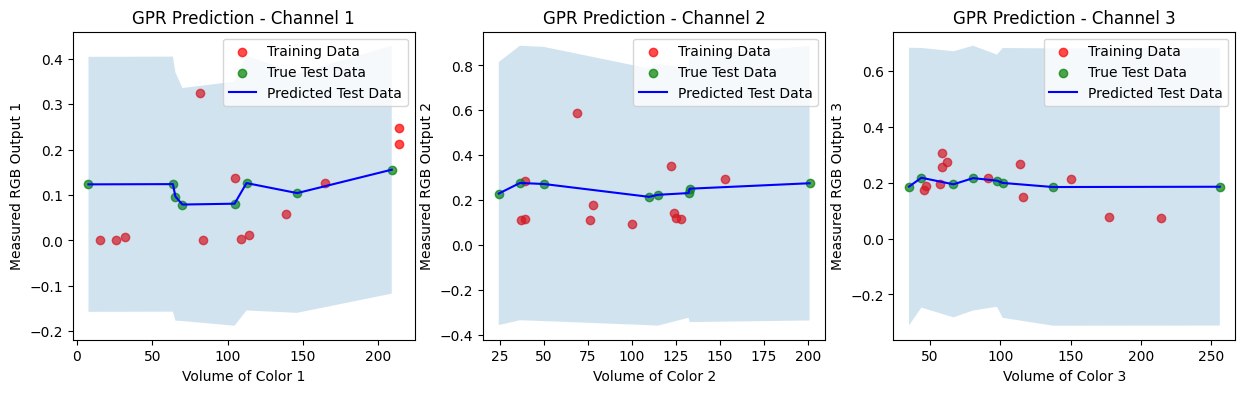

In [26]:
plt.figure(figsize=(15, 4))
# Plot the results for each RGB channel in separate 2D plots
for i in range(3):
    pair = np.array([df_xtest.numpy()[:, i],mean[:, i],sigma[:, i]]).transpose()
    pair = pair[pair[:,0].argsort()]

    plt.subplot(1,3,i+1)
    # Plot training data
    plt.scatter(df_x[:, i], df_y[:, i], c='r', label='Training Data', alpha=0.7)

    # Plot true test data
    plt.scatter(df_xtest[:, i], predictions.mean[:, i], c='g', label='True Test Data', alpha=0.7)

    # Plot predicted test data
    #plt.plot(X_test[:, i], y_pred[:, i], 'b-', label='Predicted Test Data')
    plt.plot(pair[:,0], pair[:,1], 'b-', label='Predicted Test Data')

    # Fill uncertainty region
    #plt.fill_between(X_test[:, i], y_pred[:, i].shape - 1.96 * sigma[:, i] ,y_pred[:, i] + 1.96 * sigma[:, i], alpha=0.2)
    plt.fill_between(pair[:,0], pair[:,1] - 1.96 * pair[:,2] ,pair[:,1] + 1.96 * pair[:,2] , alpha=0.2)

    plt.title(f'GPR Prediction - Channel {i+1}')
    plt.xlabel(f'Volume of Color {i+1}')
    plt.ylabel(f'Measured RGB Output {i+1}')
    plt.legend()
plt.show()

#Bayesian Optimization